# Etapa 5: Cálculo e Inversión del Factor de Calidad (Q)

Este notebook implementa el **Paso 5**: el ajuste final y la estimación del **Factor de Calidad ($Q$)** a partir de la distribución tiempo-frecuencia calculada por MPD.

### Metodología de Inversión
1. **Isolíneas Chi ($\chi = f \cdot t$):** Se proyecta la distribución TF sobre isolíneas de $X = t \cdot f$.
2. **Integración de Energía:** Se integran las amplitudes al cuadrado a lo largo de cada trayectoria de $X$.
3. **Ganancia Observada:** Se normaliza la curva de amplitud y se aplica la fórmula de compensación de Wang.
4. **Minimización de Residual:** Se compara la ganancia observada contra el catálogo teórico, evaluando el error residual:
   $$Q_{\text{opt}} = \arg\min_Q \sum_X \left| \text{Gan}_{\text{datos}}(X) - \text{Gan}_{\text{teórica}}(X, Q) \right|$$

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

MODULE_DIR = os.path.abspath('../3_Python_Code')
if MODULE_DIR not in sys.path:
    sys.path.insert(0, MODULE_DIR)

from config import QInversionConfig
from q_estimation import estimate_q_from_tfdist, extract_chi_isoline_curve

# Cargar la distribución tiempo-frecuencia generada en la Etapa 3
data = np.load('data_processed/tfdist_results.npz')
tfdist = data['tfdist']
t_vec = data['t_vec']
f_eval = data['f_eval']
print(f'Distribución TF cargada: {tfdist.shape}')

Distribución TF cargada: (1001, 88)


## 1. Inversión del Factor Q

In [2]:
q_cfg = QInversionConfig(
    q_min=10.0,
    q_max=120.0,
    dq=0.5,
    x_min=1.0,
    x_max=220.0,
    dx=1.0,
    gain_limit_db=20.0
)

results = estimate_q_from_tfdist(
    tfdist=tfdist,
    time_vector=t_vec,
    freq_vector=f_eval,
    q_config=q_cfg
)

q_est = results['q_estimated']
print('=' * 60)
print(f'  FACTOR DE CALIDAD ESTIMADO: Q = {q_est:.1f}')
print('=' * 60)

  FACTOR DE CALIDAD ESTIMADO: Q = 16.5


## 2. Panel Diagnóstico de Control de Calidad de la Inversión

Analizamos de forma integrada las 4 componentes del proceso de inversión:
1. Espectrograma TF con energía de átomos.
2. Curva observada de amplitudes sobre isolíneas Chi.
3. Comparación entre la ganancia de los datos y la ganancia teórica óptima.
4. Curva de error residual mostrando la convexidad y la ubicación del mínimo global.

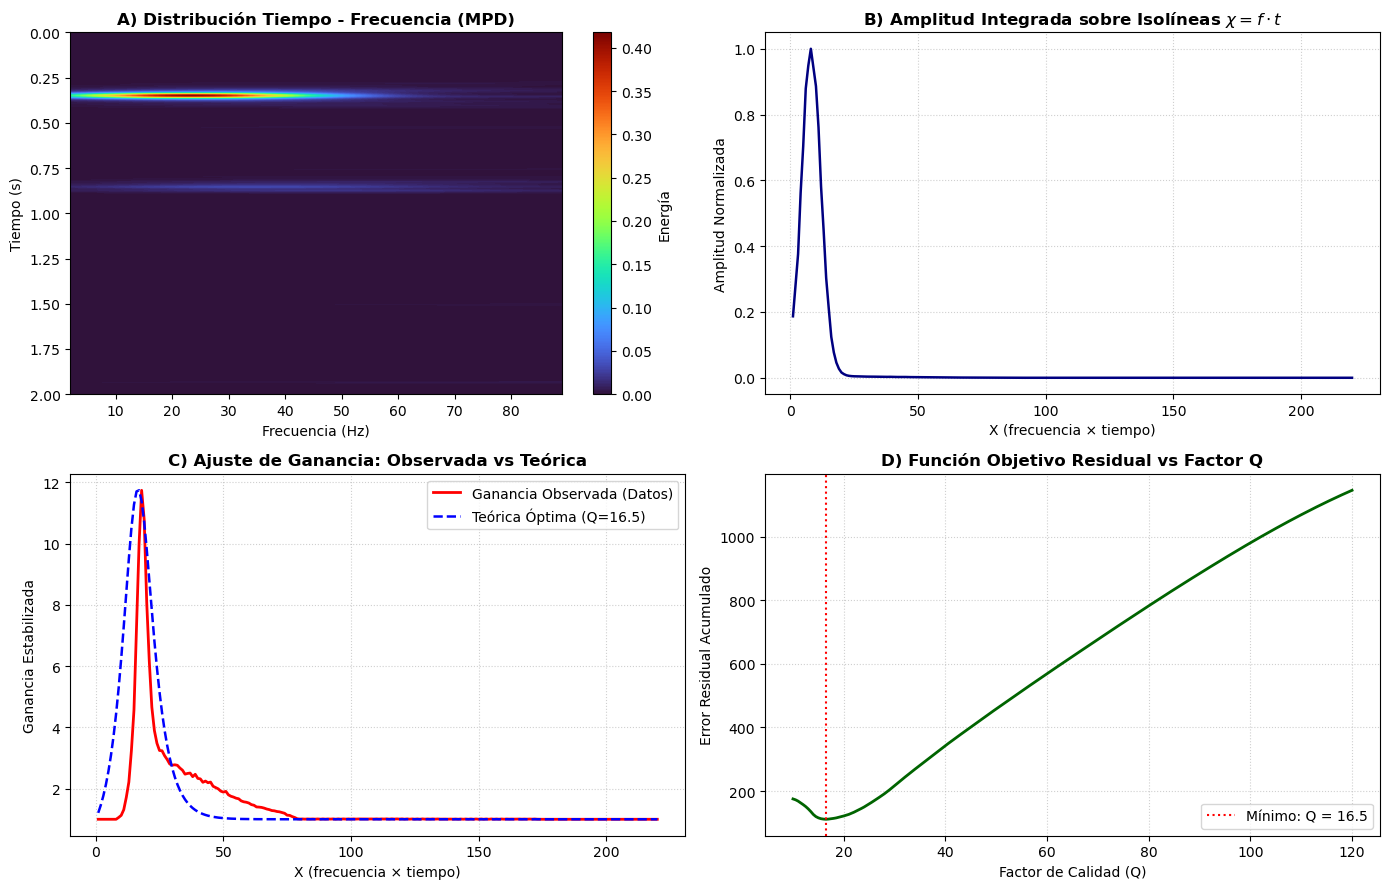

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Panel 1: Espectrograma MPD
im = axes[0, 0].imshow(
    tfdist,
    extent=[f_eval[0], f_eval[-1], t_vec[-1], t_vec[0]],
    aspect='auto',
    cmap='turbo'
)
axes[0, 0].set_title('A) Distribución Tiempo - Frecuencia (MPD)', fontweight='bold')
axes[0, 0].set_xlabel('Frecuencia (Hz)')
axes[0, 0].set_ylabel('Tiempo (s)')
plt.colorbar(im, ax=axes[0, 0], label='Energía')

# Panel 2: Amplitud integrada en isolíneas Chi
x_vec = results['x_vector']
axes[0, 1].plot(x_vec, results['amp_x_norm'], color='navy', linewidth=1.8)
axes[0, 1].set_title('B) Amplitud Integrada sobre Isolíneas $\\chi = f \\cdot t$', fontweight='bold')
axes[0, 1].set_xlabel('X (frecuencia × tiempo)')
axes[0, 1].set_ylabel('Amplitud Normalizada')
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# Panel 3: Ajuste de ganancias
axes[1, 0].plot(x_vec, results['gan_datos'], 'r-', label='Ganancia Observada (Datos)', linewidth=2.0)
axes[1, 0].plot(x_vec, results['gan_teorica_opt'], 'b--', label=f'Teórica Óptima (Q={q_est:.1f})', linewidth=1.8)
axes[1, 0].set_title('C) Ajuste de Ganancia: Observada vs Teórica', fontweight='bold')
axes[1, 0].set_xlabel('X (frecuencia × tiempo)')
axes[1, 0].set_ylabel('Ganancia Estabilizada')
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

# Panel 4: Función objetivo residual vs Q
q_vec = results['q_vector']
axes[1, 1].plot(q_vec, results['residuals'], color='darkgreen', linewidth=2.0)
axes[1, 1].axvline(q_est, color='red', linestyle=':', label=f'Mínimo: Q = {q_est:.1f}')
axes[1, 1].set_title('D) Función Objetivo Residual vs Factor Q', fontweight='bold')
axes[1, 1].set_xlabel('Factor de Calidad (Q)')
axes[1, 1].set_ylabel('Error Residual Acumulado')
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 3. Conclusiones e Interpretación Geofísica

* El algoritmo Matching Pursuit permite aislar con precisión la dispersión y decaimiento de energía en el plano $(t, f)$.
* La regularización de Wang evita que las altas frecuencias dominen el cálculo de ganancia, manteniendo el proceso estable ante ruido.
* La curva residual presenta un mínimo global bien definido, proporcionando una estimación robusta y reproducible del factor $Q$.